Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


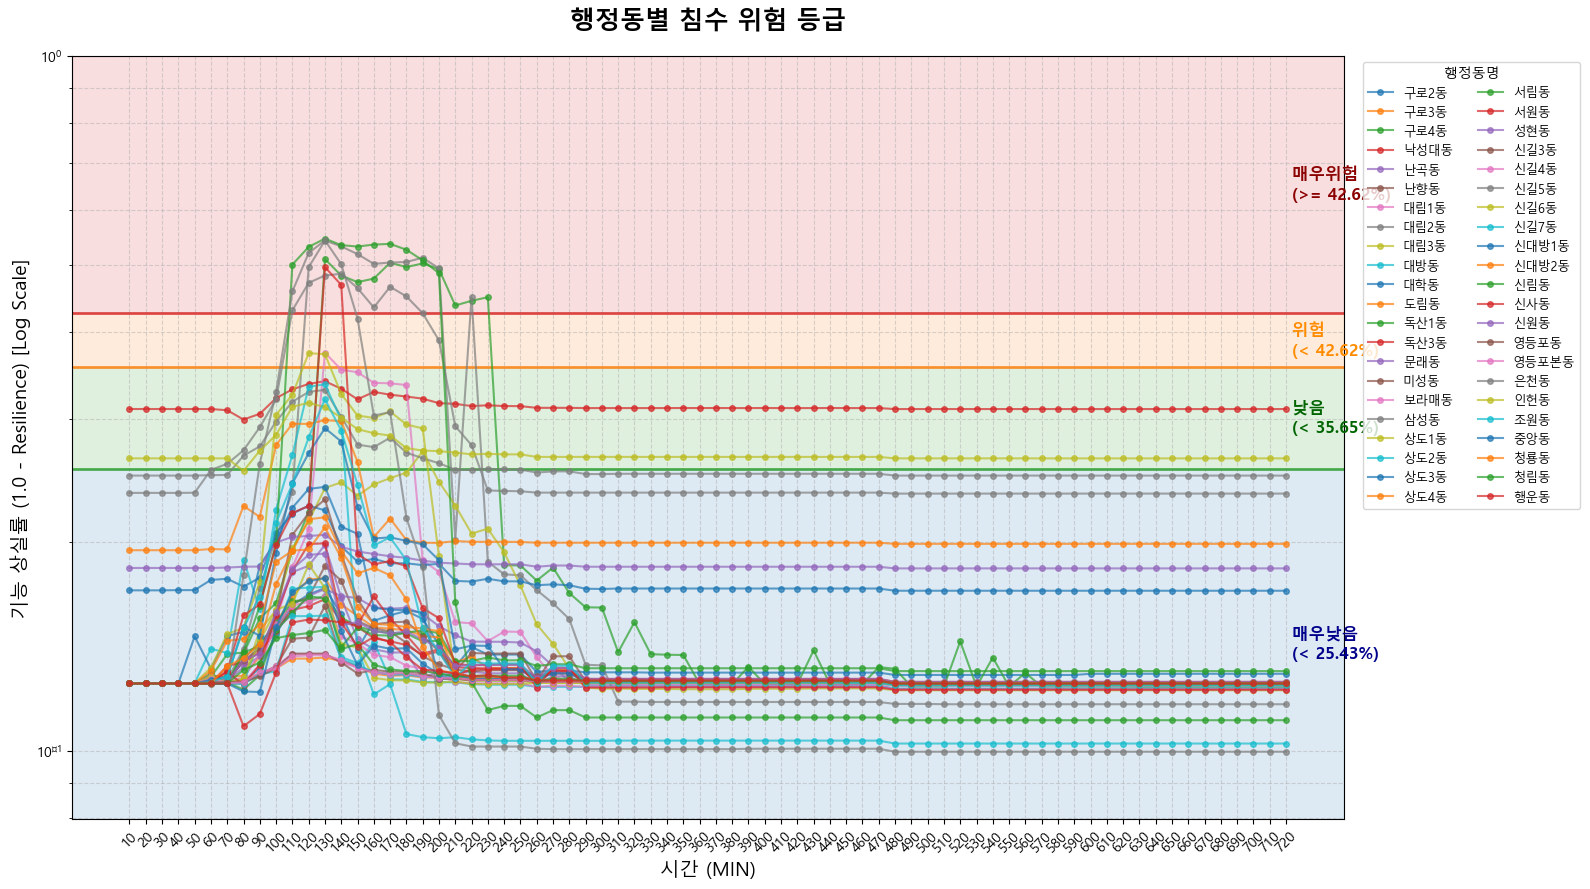

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import re
import os
import numpy as np

# --- 1. 환경 설정 ---
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

file_pattern = 'H_*MIN_region_results_final.csv'

# --- 2. 데이터 수집 ---
file_list = glob.glob(file_pattern)
data = []

exclude_regions = ['신도림동', '가리봉동', '가산동', '당산1동', '구로5동']

for file in file_list:
    match = re.search(r'(\d+)MIN', file)
    if match:
        time_min = int(match.group(1))
        try:
            df = pd.read_csv(file, encoding='utf-8')
        except UnicodeDecodeError:
            try:
                df = pd.read_csv(file, encoding='cp949')
            except UnicodeDecodeError:
                df = pd.read_csv(file, encoding='euc-kr')
            
        region_col = 'ADM_NM_y'
        
        if region_col in df.columns and 'Resilience' in df.columns:
            df_filtered = df.dropna(subset=[region_col, 'Resilience'])
            df_filtered = df_filtered[~df_filtered[region_col].isin(exclude_regions)]
            
            for _, row in df_filtered.iterrows():
                data.append({'Time': time_min, 'Region': row[region_col], 'Resilience': row['Resilience']})

df_all = pd.DataFrame(data)

if not df_all.empty:
    # --- 3. 데이터 피벗 및 기능상실률 계산 ---
    df_pivot = df_all.pivot_table(index='Time', columns='Region', values='Resilience').sort_index()
    
    # ★ [핵심 해결책] 피해가 0인 값은 바닥에 억지로 그리지 않고 투명(NaN) 처리
    df_loss = 1.0 - df_pivot
    df_loss[df_loss <= 0] = np.nan  
    
    # 실제 데이터가 존재하는 최하단 값 찾기
    y_min_actual = df_loss.min().min()
    if pd.isna(y_min_actual) or y_min_actual <= 0:
        y_min_actual = 0.001 # 예외 처리
        
    # Y축 하한선을 실제 최솟값보다 아주 살짝 아래로 설정하여 화면에 꽉 차게 만듦
    Y_MIN = y_min_actual * 0.8
    Y_MAX = 1.0
    
    # --- 4. 데이터 분포(Natural Breaks) 기반 경계 도출 알고리즘 ---
    peak_losses = df_loss.max().dropna() # NaN 무시하고 실제 최대치만 추출
    log_peaks = np.log10(peak_losses)
    sorted_log_peaks = np.sort(log_peaks)
    
    gaps = np.diff(sorted_log_peaks)
    largest_gap_indices = np.argsort(gaps)[-3:]
    
    thresholds_log = (sorted_log_peaks[largest_gap_indices] + sorted_log_peaks[largest_gap_indices + 1]) / 2
    thresholds = 10 ** np.sort(thresholds_log) 
    
    t_low = thresholds[0]   
    t_mid = thresholds[1]   
    t_high = thresholds[2]  
    
    # --- 5. 시각화 ---
    plt.figure(figsize=(16, 9))
    
    # [위험 등급 배경 음영 설정]
    plt.axhspan(t_high, Y_MAX, color='#d62728', alpha=0.15)
    plt.axhline(y=t_high, color='#d62728', linestyle='-', linewidth=2, alpha=0.8)
    
    plt.axhspan(t_mid, t_high, color='#ff7f0e', alpha=0.15)
    plt.axhline(y=t_mid, color='#ff7f0e', linestyle='-', linewidth=2, alpha=0.8)
    
    plt.axhspan(t_low, t_mid, color='#2ca02c', alpha=0.15)
    plt.axhline(y=t_low, color='#2ca02c', linestyle='-', linewidth=2, alpha=0.8)
    
    # 파란색 배경을 실제 데이터 최하단(Y_MIN)까지만 깔기
    plt.axhspan(Y_MIN, t_low, color='#1f77b4', alpha=0.15)
    
    # 선 그래프 (NaN 값은 그려지지 않으므로 밑바닥 일직선이 사라짐)
    for region in df_loss.columns:
        plt.plot(df_loss.index, df_loss[region], marker='o', markersize=4, alpha=0.7, label=region)
        
    # [우측 텍스트 라벨]
    last_time = df_loss.index[-1]
    
    mid_high = 10 ** ((np.log10(t_high) + np.log10(Y_MAX)) / 2)
    mid_mid = 10 ** ((np.log10(t_mid) + np.log10(t_high)) / 2)
    mid_low = 10 ** ((np.log10(t_low) + np.log10(t_mid)) / 2)
    mid_vlow = 10 ** ((np.log10(Y_MIN) + np.log10(t_low)) / 2)

    plt.text(last_time, mid_high, f' 매우위험\n (>= {t_high*100:.2f}%)', color='darkred', fontsize=12, fontweight='bold', va='center')
    plt.text(last_time, mid_mid, f' 위험\n (< {t_high*100:.2f}%)', color='darkorange', fontsize=12, fontweight='bold', va='center')
    plt.text(last_time, mid_low, f' 낮음\n (< {t_mid*100:.2f}%)', color='darkgreen', fontsize=12, fontweight='bold', va='center')
    plt.text(last_time, mid_vlow, f' 매우낮음\n (< {t_low*100:.2f}%)', color='darkblue', fontsize=12, fontweight='bold', va='center')

    plt.title('행정동별 침수 위험 등급', fontsize=18, fontweight='bold', pad=20)
    plt.xlabel('시간 (MIN)', fontsize=14)
    plt.ylabel('기능 상실률 (1.0 - Resilience) [Log Scale]', fontsize=14)
    
    plt.yscale('log')
    # ★ 여백 없이 화면에 꽉 차게 Y축 설정
    plt.ylim([Y_MIN, Y_MAX]) 
    
    plt.xticks(df_loss.index, rotation=45)
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    
    plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', ncol=2, fontsize=9, title="행정동명")
    plt.tight_layout()
    plt.show()